# 09 · Demostración de predicción con `src/predict.py`

**Responsable:** Joan · **Objetivo:** mostrar, con ejemplos visibles, cómo se **usa** el modelo final para predecir (para el informe y las diapositivas).

**Este notebook es ilustrativo: no se usa para decidir ni cambiar nada del modelo.** Carga `models/lgbm_final.joblib` (generado por el notebook 07) y llama a `predecir_dia`, la función de punta a punta de `src/predict.py`.

**Límites que hay que tener presentes:**
- El dataset **no trae pronósticos meteorológicos reales** de 2012. En los ejemplos con días reales, el **clima observado hace de «pronóstico»**: es el mejor caso posible, porque un pronóstico real sería menos preciso (el efecto del error del clima se midió en el notebook 08: +6 % de RMSLE con ±2 °C, ±10 puntos de humedad y 10 % de cambios de categoría).
- Los días del test se usan **solo para mostrar**; no se eligieron para dar un buen resultado sino con una regla fija (sección 2).
- El escenario «mañana» (sección 3) es **sintético**: no es una predicción de la demanda real de ningún día.

**Estado de las afirmaciones:** se indica si cada afirmación está verificada con el código de este notebook, es una hipótesis o está pendiente.

## 1) Carga del modelo y de los datos

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG
from src.data_loader import load_data
from src.predict import cargar_modelo, predecir_dia, validar_pronostico, ESCALAS

sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "joan" / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre): fig.savefig(FIG_DIR / f"{nombre}.png", dpi=130, bbox_inches="tight")

if not CONFIG["modelo_final"]["ruta"].exists():
    raise FileNotFoundError("Falta models/lgbm_final.joblib: ejecute antes notebooks/07_evaluacion_final_test.ipynb "
                            "(este notebook no regenera el modelo por su cuenta).")
modelo = cargar_modelo()
df = load_data()
pred_test = pd.read_csv(CONFIG["dir_reports"] / "joan" / "test_predicciones.csv", index_col=0, parse_dates=True)
print("Modelo:", modelo["horizonte"], "| entrenado hasta", modelo["entrenado_con"]["hasta"], "| lags:", modelo["lags"])

def pronostico_de(dia):
    """Pronóstico de 24 horas en unidades físicas, tomado del clima OBSERVADO del día (hace de pronóstico)."""
    t = df.loc[dia]
    return pd.DataFrame({"hr": t["hr"].to_numpy(), "weathersit": t["weathersit"].to_numpy(), "temp_c": t["temp"].to_numpy() * ESCALAS["temp"],
                         "atemp_c": t["atemp"].to_numpy() * ESCALAS["atemp"], "hum_pct": t["hum"].to_numpy() * ESCALAS["hum"],
                         "windspeed_kmh": t["windspeed"].to_numpy() * ESCALAS["windspeed"]})

def historial_antes_de(dia):
    return df["cnt"].loc[:pd.Timestamp(dia) - pd.Timedelta(hours=1)]

def metricas_dia(real, pred):
    e = np.log1p(np.asarray(real, float)) - np.log1p(np.asarray(pred, float))
    return float(np.sqrt(np.mean(e ** 2))), float((np.sum(pred) / np.sum(real) - 1) * 100)

Modelo: día siguiente (24 h), pronóstico emitido a las 00:00 | entrenado hasta 2012-06-30 23:00:00 | lags: ('lag_24', 'lag_168', 'lag_336')


### Punto de control 1

In [2]:
assert modelo["entrenado_con"]["hasta"] == "2012-06-30 23:00:00" and modelo["lags"] == ("lag_24", "lag_168", "lag_336")
assert len(pred_test) == 4376
print(" Modelo cargado (entrenado solo hasta 2012-06-30) y predicciones del test disponibles para comparar.")

 Modelo cargado (entrenado solo hasta 2012-06-30) y predicciones del test disponibles para comparar.


## 2) Dos días reales del test: uno de verano y uno de invierno
**Regla fija para elegir los días (no se buscan los mejores):** de cada mes (julio para el verano, diciembre para el invierno) se toman los días **laborables, completos (24 horas), sin feriado y sin horas de clima adverso**, y de ellos el que tiene un RMSLE diario **más cercano a la mediana** de esos días. Es decir, un día típico, ni el mejor ni el peor. (El RMSLE diario sale de las predicciones guardadas del notebook 07, que ya fueron una evaluación única; aquí solo sirve para elegir qué mostrar.)

In [3]:
o = pred_test.copy(); o["dia"] = o.index.normalize(); o["e"] = np.log1p(o["y"]) - np.log1p(o["pred"])
res = o.groupby("dia").agg(horas=("y", "size"), rmsle=("e", lambda s: float(np.sqrt((s ** 2).mean()))))
res["laborable"] = [int(df.loc[str(d.date()), "workingday"].iloc[0]) for d in res.index]
res["feriado"] = [int(df.loc[str(d.date()), "holiday"].iloc[0]) for d in res.index]
res["adverso_h"] = [int((df.loc[str(d.date()), "weathersit"] >= 3).sum()) for d in res.index]
cand = res[(res["horas"] == 24) & (res["laborable"] == 1) & (res["feriado"] == 0) & (res["adverso_h"] == 0)]

def dia_tipico(mes):
    c = cand[cand.index.month == mes]
    mediana = c["rmsle"].median()
    return c.index[(c["rmsle"] - mediana).abs().argmin()], len(c), mediana

DIAS = {}
for etiqueta, mes in [("verano (julio)", 7), ("invierno (diciembre)", 12)]:
    d, n, med = dia_tipico(mes); DIAS[etiqueta] = str(d.date())
    print(f"{etiqueta}: {n} días candidatos, mediana del RMSLE diario {med:.3f} -> día elegido {d.date()} ({d.day_name()}) con RMSLE {res.loc[d, 'rmsle']:.3f}")

verano (julio): 13 días candidatos, mediana del RMSLE diario 0.222 -> día elegido 2012-07-13 (Friday) con RMSLE 0.222
invierno (diciembre): 9 días candidatos, mediana del RMSLE diario 0.272 -> día elegido 2012-12-12 (Wednesday) con RMSLE 0.272


### Punto de control 2

In [4]:
assert all(pd.Timestamp(d).month in (7, 12) for d in DIAS.values())
assert all(cand.index.isin(res.index))
print(" Días elegidos por regla fija:", DIAS)

 Días elegidos por regla fija: {'verano (julio)': '2012-07-13', 'invierno (diciembre)': '2012-12-12'}


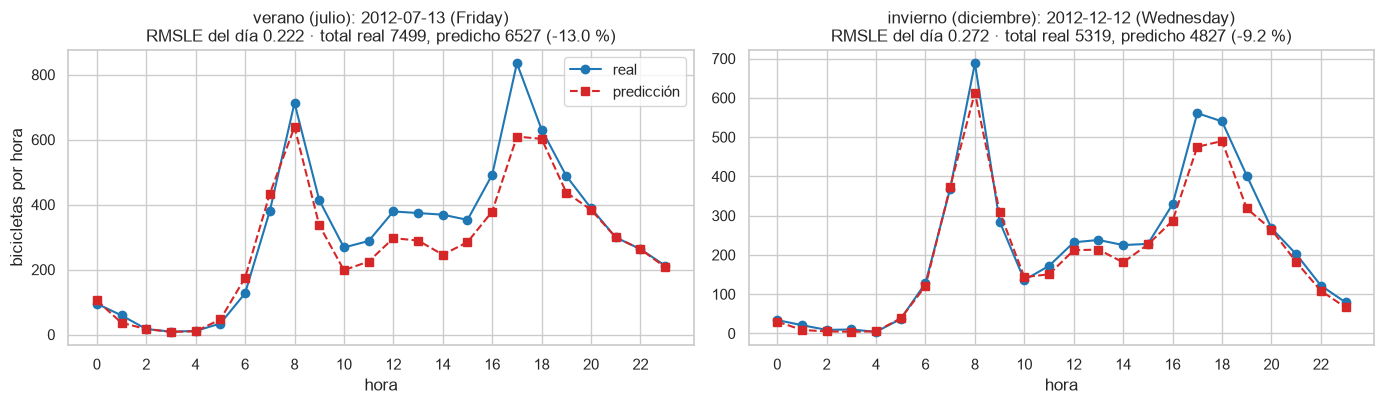

,RMSLE,total real,total predicho,error del total %,MAE (bicicletas),temp media °C
día,,,,,,
2012-07-13,0.22,7499.0,6527.13,-12.96,50.79,30.0
2012-12-12,0.27,5319.0,4827.23,-9.25,23.72,12.2


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=False)
tabla = []
for a, (etiqueta, dia) in zip(ax, DIAS.items()):
    pron = pronostico_de(dia); hist = historial_antes_de(dia)
    pred = predecir_dia(dia, pron, hist, feriado=bool(df.loc[dia, "holiday"].iloc[0]), modelo=modelo)
    real = df.loc[dia, "cnt"].to_numpy(); p = pred["prediccion"].to_numpy()
    # La demostración reproduce exactamente las predicciones guardadas del notebook 07
    assert np.allclose(p, pred_test.loc[dia, "pred"].to_numpy(), atol=1e-6)
    r, err = metricas_dia(real, p)
    a.plot(range(24), real, "o-", color="#1f77b4", label="real"); a.plot(range(24), p, "s--", color="#d62728", label="predicción")
    a.set_title(f"{etiqueta}: {dia} ({pd.Timestamp(dia).day_name()})\nRMSLE del día {r:.3f} · total real {real.sum():.0f}, predicho {p.sum():.0f} ({err:+.1f} %)")
    a.set_xlabel("hora"); a.set_xticks(range(0, 24, 2))
    tabla.append({"día": dia, "RMSLE": r, "total real": real.sum(), "total predicho": p.sum(), "error del total %": err, "MAE (bicicletas)": float(np.abs(real - p).mean()),
                  "temp media °C": float(pron["temp_c"].mean())})
ax[0].set_ylabel("bicicletas por hora"); ax[0].legend()
plt.tight_layout(); guardar(fig, "22_demo_dos_dias"); plt.show()
display(pd.DataFrame(tabla).set_index("día").round(2))

### Punto de control 3: lo que se muestra es exactamente lo que predice `predict.py`

In [6]:
assert len(tabla) == 2 and all(np.isfinite(list(t.values())[1:]).all() for t in tabla)
print(" Las predicciones mostradas coinciden con las del notebook 07 (diferencia < 1e-6).")

 Las predicciones mostradas coinciden con las del notebook 07 (diferencia < 1e-6).


**Interpretación.** La regla fija eligió dos días típicos (no los mejores): el **viernes 2012-07-13** (verano; 13 días candidatos, RMSLE diario mediano 0.222) y el **miércoles 2012-12-12** (invierno; 9 candidatos, mediana 0.272). Para referencia, la mediana del RMSLE diario de todo el test es 0.267.

| Día | Temperatura media | RMSLE | Total real | Total predicho | MAE |
| :--- | :---: | :---: | :---: | :---: | :---: |
| 2012-07-13 (verano) | 30.0 °C | 0.222 | 7 499 | 6 527 (−13.0 %) | 50.8 bicicletas/hora |
| 2012-12-12 (invierno) | 12.2 °C | 0.272 | 5 319 | 4 827 (−9.2 %) | 23.7 bicicletas/hora |

- **El modelo reproduce la forma del día:** los dos picos laborales (8:00 y 17:00–18:00), el valle de media mañana y la madrugada casi sin demanda. En invierno el ajuste es muy cercano.
- **Subestima en ambos días** (−9 % y −13 % en el total), coherente con el sesgo de −6.9 % medido en el test. En el día de verano la diferencia está en el pico de las 17:00 (609 predichas frente a 835 reales) y en el mediodía (a las 12:00 y 13:00, 297 y 289 predichas frente a 379 y 374 reales).
- Las predicciones son **exactamente** las guardadas del notebook 07 (diferencia < 1e-6): la demostración usa el mismo modelo y no re-evalúa nada.

## 3) Escenario «mañana» hecho a mano (datos sintéticos)
Así se usaría la función con entradas de un usuario: un **pronóstico de 24 horas escrito a mano** y un **historial de demanda sintético** (el de los 14 días previos, que necesitan los tres lags). **Todo esto es sintético**: no es una predicción de la demanda real de ningún día. La fecha («mañana») es el 2013-04-16, **fuera del rango de entrenamiento** (2011-2012), por lo que `predict.py` avisa y usa `yr = 1` como proxy del nivel más reciente.

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
hr,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
weathersit,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
temp_c,7.8,7.1,6.7,6.5,6.7,7.3,8.2,9.3,10.8,12.5,...,20.2,20.5,20.2,19.3,17.9,16.2,14.3,12.5,10.8,9.3
atemp_c,6.8,6.1,5.7,5.5,5.7,6.3,7.2,8.3,9.8,11.5,...,19.2,19.5,19.2,18.3,16.9,15.2,13.3,11.5,9.8,8.3
hum_pct,75.0,75.0,75.0,74.0,74.0,73.0,72.0,70.0,68.0,65.0,...,51.0,50.0,51.0,52.0,55.0,58.0,62.0,65.0,68.0,70.0
windspeed_kmh,12.0,9.0,9.0,9.0,9.0,12.0,9.0,9.0,9.0,9.0,...,9.0,12.0,9.0,9.0,9.0,9.0,12.0,9.0,9.0,9.0


Historial sintético: 336 horas | demanda media: 210.1 (la media de train es 167.7 )
Avisos de predict.py: ['el modelo se entrenó con 2011-2012; se usa yr = 1 como proxy del nivel más reciente']


fecha_hora,2013-04-16 00:00:00,2013-04-16 01:00:00,2013-04-16 02:00:00,2013-04-16 03:00:00,2013-04-16 04:00:00,2013-04-16 05:00:00,2013-04-16 06:00:00,2013-04-16 07:00:00,2013-04-16 08:00:00,2013-04-16 09:00:00,...,2013-04-16 14:00:00,2013-04-16 15:00:00,2013-04-16 16:00:00,2013-04-16 17:00:00,2013-04-16 18:00:00,2013-04-16 19:00:00,2013-04-16 20:00:00,2013-04-16 21:00:00,2013-04-16 22:00:00,2013-04-16 23:00:00
prediccion,18.8,7.5,3.5,2.4,2.7,16.0,89.1,286.7,519.5,260.5,...,163.0,192.0,288.9,542.6,531.1,304.9,185.1,143.9,90.5,50.2
lags_faltantes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


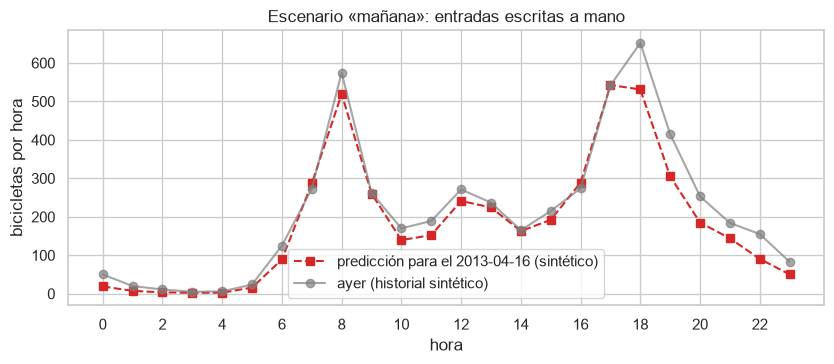

In [7]:
FECHA = pd.Timestamp("2013-04-16")                       # un martes, sin feriado
horas = np.arange(24)
# Pronóstico escrito a mano (unidades físicas): día templado, nubosidad ligera por la tarde
temp = 11 + 9 * np.sin((horas - 9) / 24 * 2 * np.pi).clip(-1, 1) * 0.5 + 5 * np.exp(-((horas - 15) ** 2) / 30)
pron_manual = pd.DataFrame({"hr": horas, "weathersit": np.where(horas >= 14, 2, 1), "temp_c": np.round(temp, 1),
                            "atemp_c": np.round(temp - 1.0, 1), "hum_pct": np.round(75 - 25 * np.exp(-((horas - 15) ** 2) / 40), 0),
                            "windspeed_kmh": np.where(horas % 5 == 0, 12.0, 9.0)})
display(pron_manual.T)

# Historial sintético: perfil medio por (hora, tipo de día) de train, escalado a un nivel reciente y con ruido; 14 días previos
tr = df.loc[:"2012-06-30"].dropna(subset=["cnt"]); perfil = tr.groupby(["hr", "workingday"])["cnt"].mean()
idx = pd.date_range(FECHA - pd.Timedelta(days=14), FECHA - pd.Timedelta(hours=1), freq="h")
rng = np.random.default_rng(42)
base = np.array([perfil[(t.hour, int(t.dayofweek < 5))] for t in idx])
hist_sint = pd.Series(np.round(base * 1.25 * rng.lognormal(0, 0.12, len(idx))), index=idx, name="cnt")
print("Historial sintético:", len(hist_sint), "horas | demanda media:", round(hist_sint.mean(), 1), "(la media de train es", round(tr['cnt'].mean(), 1), ")")

with warnings.catch_warnings(record=True) as aviso:
    warnings.simplefilter("always")
    pred_manana = predecir_dia(FECHA, pron_manual, hist_sint, feriado=False, modelo=modelo)
print("Avisos de predict.py:", [str(a.message)[:110] for a in aviso])
display(pred_manana.round(1).T)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(range(24), pred_manana["prediccion"], "s--", color="#d62728", label="predicción para el 2013-04-16 (sintético)")
ax.plot(range(24), hist_sint.iloc[-24:].to_numpy(), "o-", color="gray", alpha=0.7, label="ayer (historial sintético)")
ax.set_xlabel("hora"); ax.set_ylabel("bicicletas por hora"); ax.set_xticks(range(0, 24, 2)); ax.legend(); ax.set_title("Escenario «mañana»: entradas escritas a mano")
plt.tight_layout(); guardar(fig, "23_demo_manana_sintetico"); plt.show()

### Qué pasa con entradas inválidas (la validación de esquema)

In [8]:
invalidas = {
    "temperatura de 99 °C": pron_manual.assign(temp_c=99.0),
    "solo 23 horas": pron_manual.iloc[:23],
    "falta la humedad": pron_manual.drop(columns="hum_pct"),
    "weathersit = 7": pron_manual.assign(weathersit=7),
    "valores vacíos": pron_manual.assign(windspeed_kmh=[np.nan] + [10.0] * 23),
}
rechazos = {}
for nombre, p in invalidas.items():
    try:
        predecir_dia(FECHA, p, hist_sint, modelo=modelo); rechazos[nombre] = "NO RECHAZADO"
    except ValueError as e:
        rechazos[nombre] = str(e)
try:
    predecir_dia(FECHA, pron_manual, pd.concat([hist_sint, pd.Series([100.0], index=[FECHA + pd.Timedelta(hours=3)])]), modelo=modelo); rechazos["historial con una hora del día a pronosticar"] = "NO RECHAZADO"
except ValueError as e:
    rechazos["historial con una hora del día a pronosticar"] = str(e)
display(pd.Series(rechazos, name="mensaje de error").to_frame())

,mensaje de error
temperatura de 99 °C,"temp_c fuera del rango físico [-20.0, 50.0]"
solo 23 horas,el pronóstico debe tener exactamente una fila ...
falta la humedad,faltan columnas en el pronóstico: ['hum_pct']
weathersit = 7,"weathersit debe ser 1, 2, 3 o 4"
valores vacíos,el pronóstico contiene valores vacíos
historial con una hora del día a pronosticar,el historial contiene horas del día a pronosti...


### Punto de control 4

In [9]:
assert len(pred_manana) == 24 and np.isfinite(pred_manana["prediccion"]).all() and (pred_manana["prediccion"] >= 0).all()
assert (pred_manana["lags_faltantes"] == 0).all(), "el historial sintético debe cubrir los tres lags"
assert any("yr = 1" in str(a.message) for a in aviso), "debe avisar que la fecha está fuera del entrenamiento"
assert all(v != "NO RECHAZADO" for v in rechazos.values())
print(" 24 predicciones finitas y no negativas; el aviso de fecha fuera de rango se emitió; las 6 entradas inválidas se rechazaron.")

 24 predicciones finitas y no negativas; el aviso de fecha fuera de rango se emitió; las 6 entradas inválidas se rechazaron.


**Interpretación.** Con un pronóstico escrito a mano (mañana fresca y despejada, tarde nublada, de 6.5 °C a 20.5 °C) y un historial sintético de 14 días (demanda media 210.1), `predecir_dia` devuelve las 24 predicciones con **picos a las 8:00 (≈ 520 bicicletas) y a las 17:00 (≈ 543)**, el patrón de un martes laboral. `lags_faltantes` vale 0 en las 24 horas porque el historial cubre los tres lags.

- La fecha (2013-04-16) está **fuera del rango de entrenamiento**: `predict.py` lo avisa y usa `yr = 1` como proxy. Hipótesis: para fechas posteriores el modelo no ha visto el nivel real de demanda; sirve para mostrar el uso, no como predicción.
- **La validación de esquema funciona:** se rechazan con un mensaje claro una temperatura de 99 °C, un pronóstico de 23 horas, la falta de la columna de humedad, `weathersit = 7`, valores vacíos y un historial que incluye horas del día a pronosticar (protección contra el uso de datos del futuro).
- **Todo es sintético:** ni el pronóstico ni el historial son datos reales; estas predicciones no describen la demanda de ningún día.

## 4) Un caso que falla a propósito: historial incompleto o ausente
Con el día de verano de la sección 2 se quitan datos del historial. **El modelo depende de sus lags**: el notebook 08 mostró que sin ningún lag la predicción cae un 84.8 % en un día laborable normal. Aquí se ve el mismo efecto con un día real. `predict.py` emite un aviso cuando alguna hora no tiene ningún lag.

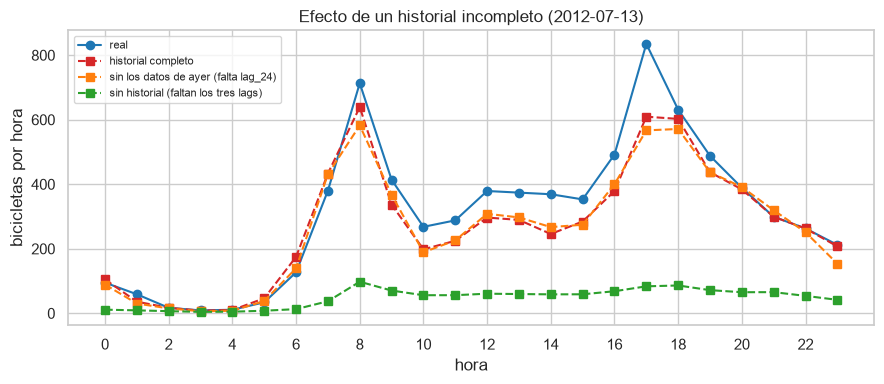

,total predicho,error del total vs real %,RMSLE del día,variación vs historial completo %
caso,,,,
historial completo,6527.13,-12.96,0.22,0.00
sin los datos de ayer (falta lag_24),6359.74,-15.19,0.25,-2.56
sin historial (faltan los tres lags),1149.82,-84.67,1.75,-82.38


Aviso de predict.py por caso: {'historial completo': [], 'sin los datos de ayer (falta lag_24)': [], 'sin historial (faltan los tres lags)': ['24 horas sin ningún lag disponible: el modelo, entrenado con lags, predice una demanda muy infe']}


In [10]:
dia = DIAS["verano (julio)"]; pron = pronostico_de(dia); hist = historial_antes_de(dia)
real = df.loc[dia, "cnt"].to_numpy()
inicio = pd.Timestamp(dia)
hist_sin_ayer = hist.copy(); hist_sin_ayer.loc[hist_sin_ayer.index >= inicio - pd.Timedelta(days=1)] = np.nan
variantes = {"historial completo": hist, "sin los datos de ayer (falta lag_24)": hist_sin_ayer, "sin historial (faltan los tres lags)": hist.iloc[:0]}
salidas, avisos_caso = {}, {}
for nombre, h in variantes.items():
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always"); salidas[nombre] = predecir_dia(dia, pron, h, modelo=modelo)["prediccion"].to_numpy()
    avisos_caso[nombre] = [str(a.message)[:95] for a in w if "ningún lag" in str(a.message)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(24), real, "o-", color="#1f77b4", label="real")
for (n, p), c in zip(salidas.items(), ["#d62728", "#ff7f0e", "#2ca02c"]): ax.plot(range(24), p, "s--", color=c, label=n)
ax.set_title(f"Efecto de un historial incompleto ({dia})"); ax.set_xlabel("hora"); ax.set_ylabel("bicicletas por hora"); ax.set_xticks(range(0, 24, 2)); ax.legend(fontsize=8)
plt.tight_layout(); guardar(fig, "24_demo_falla_sin_historial"); plt.show()
filas = []
for n, p in salidas.items():
    r, err = metricas_dia(real, p); filas.append({"caso": n, "total predicho": p.sum(), "error del total vs real %": err, "RMSLE del día": r, "variación vs historial completo %": (p.sum() / salidas["historial completo"].sum() - 1) * 100})
caida = pd.DataFrame(filas).set_index("caso"); display(caida.round(2))
print("Aviso de predict.py por caso:", avisos_caso)

### Punto de control 5

In [11]:
assert len(avisos_caso["sin historial (faltan los tres lags)"]) == 1 and len(avisos_caso["historial completo"]) == 0
assert caida.loc["sin historial (faltan los tres lags)", "variación vs historial completo %"] < -50
assert caida.loc["sin los datos de ayer (falta lag_24)", "variación vs historial completo %"] > -25
print(" Sin historial la predicción cae más de 50 %; sin ayer, menos de 25 %; el aviso solo aparece cuando no hay ningún lag.")

 Sin historial la predicción cae más de 50 %; sin ayer, menos de 25 %; el aviso solo aparece cuando no hay ningún lag.


**Interpretación.** Con el día de verano (2012-07-13) se quitan datos del historial:

| Caso | Total predicho | Error vs real | RMSLE del día | Vs historial completo | Aviso |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Historial completo | 6 527 | −13.0 % | 0.22 | — | no |
| Sin los datos de ayer (falta `lag_24`) | 6 360 | −15.2 % | 0.25 | −2.6 % | no |
| **Sin historial (faltan los tres lags)** | **1 150** | **−84.7 %** | **1.75** | **−82.4 %** | **sí** |

- **Perder solo el día anterior es tolerable** (−2.6 %: el modelo se apoya en `lag_168` y `lag_336`), pero **sin ningún lag la predicción se desploma** (de 6 527 a 1 150 bicicletas) y el RMSLE del día pasa de 0.22 a 1.75. Es el mismo efecto del notebook 08 (−84.8 % en otro día): el modelo, entrenado con lags, interpreta la ausencia como las primeras semanas de 2011, cuando la demanda era muy baja.
- `predict.py` **avisa** en el caso extremo (y solo en ese). Pendiente: falta un modelo sin lags como respaldo automático; hoy el aviso lo debe atender quien llama a la función.

## 5) Una semana de 7 días seguidos, predicha día a día
Se simula el uso diario: cada día se predice con el historial **anterior a ese día** (observado) y el clima observado como pronóstico. **Regla fija para elegir la semana:** la primera semana completa (lunes a domingo, los 7 días con 24 horas registradas) de septiembre de 2012 (mes sin eventos extremos en el test).

Semana elegida: 2012-09-03 a 2012-09-09


,feriado,RMSLE,total real,total predicho,error del total %
día,,,,,
Mon 2012-09-03,1,0.58,6034.0,5563.37,-7.80
Tue 2012-09-04,0,0.27,6864.0,6399.66,-6.76
Wed 2012-09-05,0,0.20,7112.0,6829.57,-3.97
Thu 2012-09-06,0,0.29,6203.0,6030.75,-2.78
Fri 2012-09-07,0,0.19,7504.0,6837.72,-8.88
Sat 2012-09-08,0,0.37,5976.0,4600.97,-23.01
Sun 2012-09-09,0,0.45,8227.0,5986.52,-27.23


RMSLE de la semana (168 horas): 0.360 | error del total semanal: -11.8 %


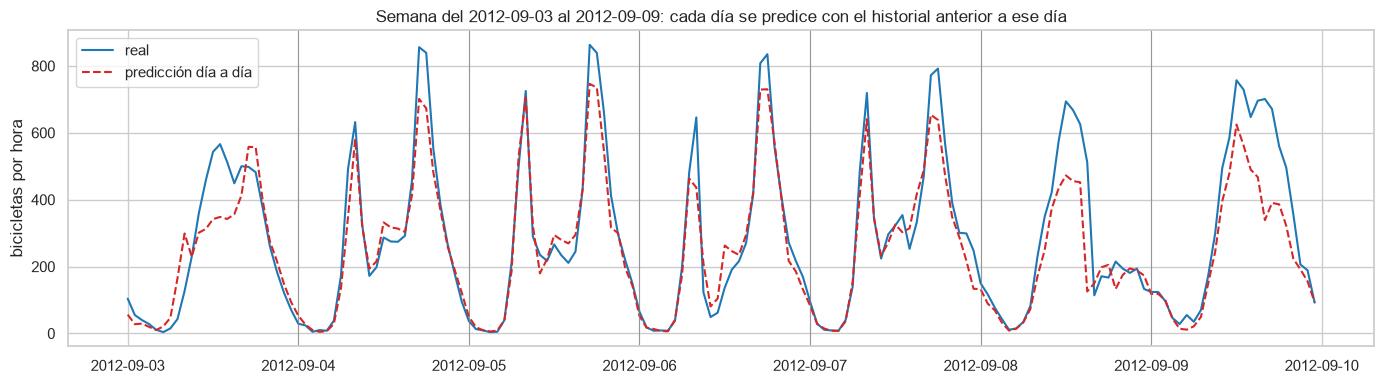

In [12]:
dias_ok = res[res["horas"] == 24].index
lunes = [d for d in pd.date_range("2012-09-01", "2012-09-24") if d.dayofweek == 0 and all((d + pd.Timedelta(days=k)) in dias_ok for k in range(7))]
inicio = lunes[0]; semana = [inicio + pd.Timedelta(days=k) for k in range(7)]
print("Semana elegida:", inicio.date(), "a", semana[-1].date())
partes, filas = [], []
for d in semana:
    s = str(d.date())
    p = predecir_dia(d, pronostico_de(s), historial_antes_de(s), feriado=bool(df.loc[s, "holiday"].iloc[0]), modelo=modelo)
    p["real"] = df.loc[s, "cnt"].to_numpy(); partes.append(p)
    r, err = metricas_dia(p["real"], p["prediccion"])
    filas.append({"día": f"{d.day_name()[:3]} {s}", "feriado": int(df.loc[s, 'holiday'].iloc[0]), "RMSLE": r, "total real": p["real"].sum(), "total predicho": p["prediccion"].sum(), "error del total %": err})
sem = pd.concat(partes); tab_sem = pd.DataFrame(filas).set_index("día")
display(tab_sem.round(2))
rm_sem = float(np.sqrt(np.mean((np.log1p(sem["real"]) - np.log1p(sem["prediccion"])) ** 2)))
print(f"RMSLE de la semana ({len(sem)} horas): {rm_sem:.3f} | error del total semanal: {(sem['prediccion'].sum() / sem['real'].sum() - 1) * 100:+.1f} %")
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(sem.index, sem["real"], color="#1f77b4", label="real"); ax.plot(sem.index, sem["prediccion"], "--", color="#d62728", label="predicción día a día")
for d in semana[1:]: ax.axvline(d, color="gray", lw=0.5)
ax.set_ylabel("bicicletas por hora"); ax.set_title(f"Semana del {inicio.date()} al {semana[-1].date()}: cada día se predice con el historial anterior a ese día"); ax.legend()
plt.tight_layout(); guardar(fig, "25_demo_semana"); plt.show()

### Punto de control 6

In [13]:
assert len(sem) == 168 and len(semana) == 7 and np.isfinite(sem.to_numpy()).all()
assert np.allclose(sem["prediccion"].to_numpy(), pred_test.loc[sem.index, "pred"].to_numpy(), atol=1e-6)
print(" 168 horas predichas día a día; coinciden con las del notebook 07.")

 168 horas predichas día a día; coinciden con las del notebook 07.


**Interpretación.** La regla fija eligió la semana del **2012-09-03 al 09-09** (primera semana completa de septiembre); **no se eligió por su resultado** y, de hecho, incluye un feriado (Labor Day) y un fin de semana mal predicho.

| Día | RMSLE | Error del total |
| :--- | :---: | :---: |
| Lun 09-03 (feriado) | 0.58 | −7.8 % |
| Mar 09-04 | 0.27 | −6.8 % |
| Mié 09-05 | 0.20 | −4.0 % |
| Jue 09-06 | 0.29 | −2.8 % |
| Vie 09-07 | 0.19 | −8.9 % |
| Sáb 09-08 | 0.37 | −23.0 % |
| Dom 09-09 | 0.45 | −27.2 % |

- **De martes a viernes el modelo acierta bien** (RMSLE 0.19–0.29, totales entre −2.8 % y −8.9 %).
- **Falla el feriado** (el lunes: el total es cercano, −7.8 %, pero el patrón horario no coincide: el máximo real fue a las 13:00 y el modelo lo ubica a las 17:00; RMSLE 0.58) y **subestima mucho el fin de semana** (−23 % y −27 %). Hipótesis: es coherente con los puntos débiles del test (feriados y no laborables), pero esta semana por sí sola no lo demuestra.
- **RMSLE de la semana: 0.360** (el RMSLE de todo el test es 0.3505) y **el total semanal queda un 11.8 % por debajo** de lo real.
- Cada día se predijo con el historial **anterior a ese día** (observado) y las 168 horas coinciden con las del notebook 07: es una simulación del uso diario, no una evaluación nueva.

## 6) Resumen y límites de esta demostración
- Se mostró que `predecir_dia` recibe un pronóstico de 24 horas y el historial anterior al día, valida el esquema y devuelve las 24 predicciones; reproduce exactamente las del notebook 07.
- **Clima observado como «pronóstico»:** es el mejor caso. No hay pronósticos reales de 2012 en el dataset. Con un pronóstico real el error sería mayor (notebook 08, sección 3).
- **Los días del test son solo ilustrativos** y no se usaron para cambiar nada del modelo; la evaluación del modelo es la del notebook 07.
- **El escenario «mañana» es sintético**: sirve para mostrar el uso, no para predecir la demanda de un día real.
- **Dependencia de los lags:** sin historial el modelo predice mucho menos; hay que completar el historial o usar un modelo sin lags (Pendiente: no implementado como respaldo).